# MNIST load check

Loads the cached MNIST from `data/` (no download) and sanity-checks it. Select the `.venv` kernel.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml  # used only to load the dataset

t0 = time.time()
X, y = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff',
                    return_X_y=True, data_home='data')
print(f'loaded in {time.time() - t0:.1f}s')

X = X.astype(np.float32) / 255.0
y = y.astype(np.int64)

loaded in 12.3s


In [2]:
print('X:', X.shape, X.dtype, 'min/max', X.min(), X.max())
print('y:', y.shape, y.dtype)
print('NaNs in X:', np.isnan(X).sum())
print('label counts:', dict(zip(*np.unique(y, return_counts=True))))

# standard split: first 60k train, last 10k test
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]
print('train', X_train.shape, 'test', X_test.shape)

X: (70000, 784) float32 min/max 0.0 1.0
y: (70000,) int64
NaNs in X: 0
label counts: {np.int64(0): np.int64(6903), np.int64(1): np.int64(7877), np.int64(2): np.int64(6990), np.int64(3): np.int64(7141), np.int64(4): np.int64(6824), np.int64(5): np.int64(6313), np.int64(6): np.int64(6876), np.int64(7): np.int64(7293), np.int64(8): np.int64(6825), np.int64(9): np.int64(6958)}
train (60000, 784) test (10000, 784)


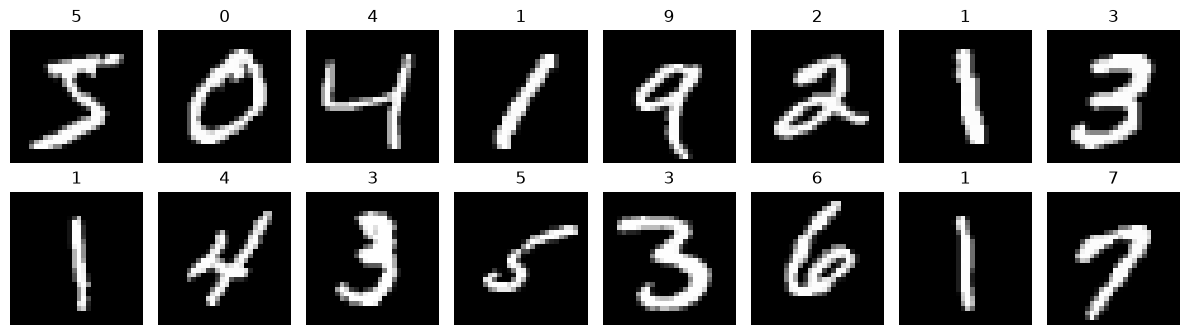

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, label in zip(axes.flat, X_train[:16], y_train[:16]):
    ax.imshow(img.reshape(28, 28), cmap='gray')
    ax.set_title(label)
    ax.axis('off')
plt.tight_layout()
plt.show()